In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

df = pd.read_csv('animation_movies_enriched_1878_2029.csv', encoding="utf-8")

In [2]:
df = df.drop(columns=['Movie_ID',
                      'Original_Title',
                      'Original_Language',
                      'Spoken_Languages',
                      'Overview',
                      'Belongs_To_Collection',
                      'All_Production_Companies',
                      'Collection_ID',
                      'Backdrop_URL',
                      'TMDB_URL',
                      'IMDb_URL',
                      'Is_Released',
                      'Is_TV_Compilation',
                      'MPAA_Rating', 
                      'Data_Quality_Score',
                      'Data_Quality_Score',
                      'Is_Adult_Content',
                      'Profitability_ROI',
                      'Poster_URL',
                      'IMDb_ID' ])

df.drop(df[df["Runtime_Needs_Verification"] == True].index, inplace=True)
df.drop(df[df['Decade'] == 'Unknown Era'].index, inplace=True)
df.drop(df[df["Animation_Style"] == 'Stop-Motion'].index, inplace=True)
df.drop(df[df["Animation_Style"] == 'Motion Capture'].index, inplace=True)

In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 20991 entries, 10 to 24549
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   TMDB_ID                     20991 non-null  int64  
 1   Movie_Name                  20991 non-null  str    
 2   Release_Year                20991 non-null  float64
 3   Release_Date                20991 non-null  str    
 4   Studio                      16361 non-null  str    
 5   Director                    19765 non-null  str    
 6   Country_Origin              20918 non-null  str    
 7   Animation_Style             20851 non-null  str    
 8   Genre                       20991 non-null  str    
 9   Theme                       20991 non-null  str    
 10  Movie_Length_Minutes        20991 non-null  float64
 11  TMDB_Rating                 15098 non-null  float64
 12  TMDB_Vote_Count             15104 non-null  float64
 13  TMDB_Popularity             20972 non-null  fl

In [4]:
df['Movie_Length_Minutes']

10        15.0
11        10.0
12         5.0
13         2.0
14         2.0
         ...  
24514     61.0
24515     85.0
24538     90.0
24547     84.0
24549    113.0
Name: Movie_Length_Minutes, Length: 20991, dtype: float64

In [5]:
plt.style.use("dark_background")

C1 = '#7C6AF7'   # purple
C2 = '#F97C6D'   # coral
C3 = '#4FC3C8'   # cyan
C4 = '#F4C542'   # yellow
GRAY = '#8B92A8'

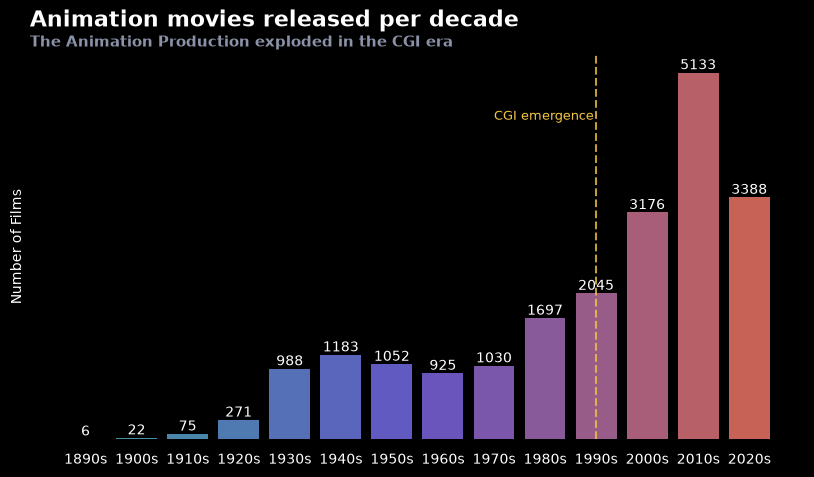

In [6]:
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

counts = df['Decade'].value_counts().sort_index()
colors = LinearSegmentedColormap.from_list('ridge', [C3, C1, C2])

# one color per bar
norm = np.linspace(0, 1, len(counts))
bar_colors = colors(norm)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=bar_colors, alpha=0.8, zorder=3)

# annotations
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2,
            height,
            int(height),
            ha='center',
            va='bottom')

cgi_idx = list(counts.index).index('1990s')
plt.axvline(x=cgi_idx, color=C4, linestyle='--', linewidth=1.5, alpha=0.8, zorder=4)
plt.text(cgi_idx - 2, counts.max() * 0.88,
        'CGI emergence', fontsize=9, color=C4, rotation=0, va='center')

ax.set_title("Animation movies released per decade",
             fontsize=16,
             weight="bold",
             loc="left",
             pad=20)

ax.text(0, 1.02,
        "The Animation Production exploded in the CGI era",
        transform=ax.transAxes,
        weight="bold",
        fontsize=11,
        color=GRAY)

sns.despine(left=True, bottom=True)

# remove Y axis
ax.set_ylabel('Number of Films')
ax.set_yticks([])
ax.tick_params(axis='x', which='both', length=0, pad=10)

plt.show()

C:\Users\jzhan\AppData\Local\Temp\ipykernel_30004\3497424110.py:62: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left')


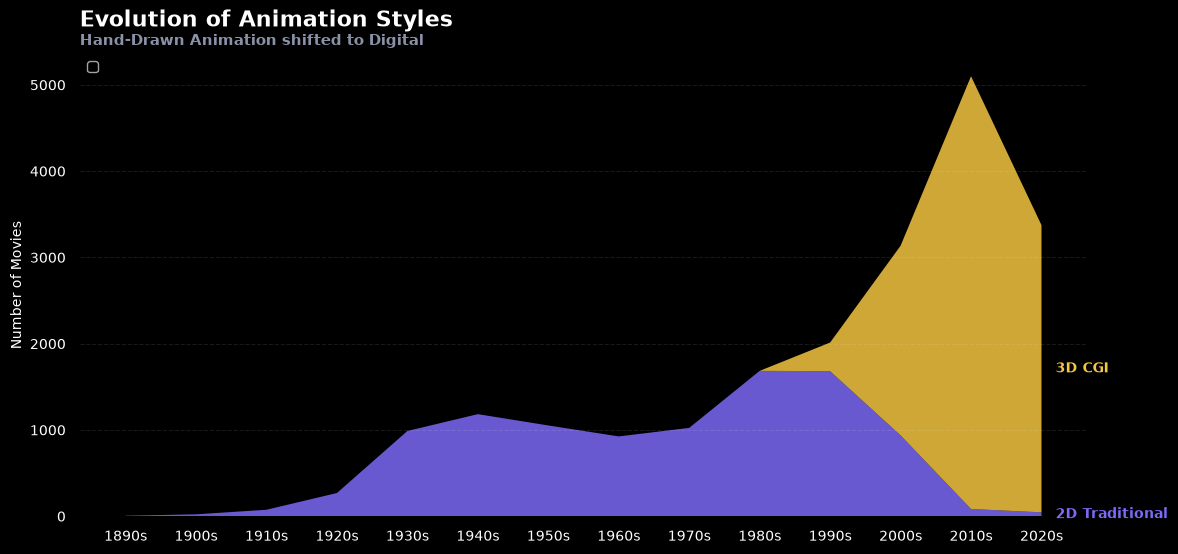

In [7]:
import matplotlib.pyplot as plt

# group
style_decade = df.groupby(['Decade', 'Animation_Style']).size().unstack(fill_value=0)

# sort
style_decade = style_decade.sort_index()

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(style_decade.index))

ax.stackplot(
    x,
    style_decade.T,
    colors=[C1, C4],
    alpha=0.85
)

# clean X labels
ax.set_xticks(x)
ax.set_xticklabels(style_decade.index)

# ── IN-CHART LABELS ──────────────────────────────
for i, col in enumerate(style_decade.columns):
    y = style_decade[col].values

    x_pos = x[-1]

    y_stack = style_decade.iloc[-1, :i+1].sum()
    y_base = style_decade.iloc[-1, :i].sum() if i > 0 else 0
    y_center = (y_stack + y_base) / 2

    ax.text(
        x_pos + 0.2,
        y_center,
        col,
        color=[C1, C4][i],
        fontsize=10,
        va='center',
        fontweight='bold'
    )

plt.title("Evolution of Animation Styles",
          fontsize=16,
          weight="bold",
          loc="left",
          pad=20)

plt.text(0, 1.02,
         "Hand-Drawn Animation shifted to Digital",
         transform=plt.gca().transAxes,
         weight="bold",
         fontsize=11,
         color=GRAY)

sns.despine(left=True, bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.1)

plt.ylabel("Number of Movies")

plt.legend(loc='upper left')

ax.tick_params(axis='y', which='both', length=0, pad=10)
ax.tick_params(axis='x', which='both', length=0, pad=10)

plt.show()

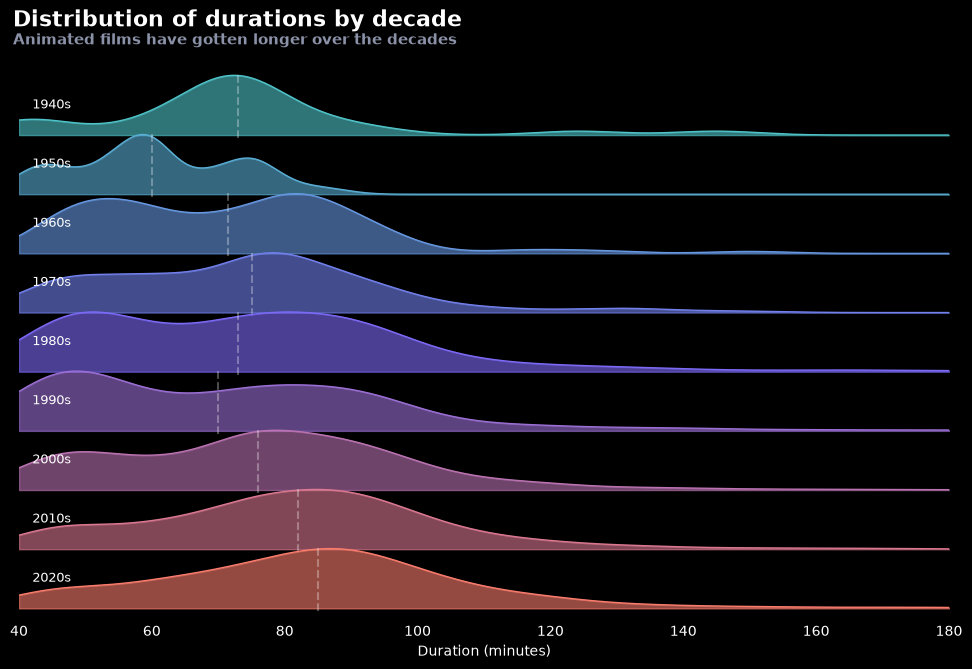

In [8]:
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import matplotlib.pyplot as plt

runtime = df[
    df['Movie_Length_Minutes'].between(40, 180) &
    df['Decade'].str.match(r'^\d{4}s$', na=False)
].copy()

runtime['Decade_num'] = runtime['Decade'].str[:4].astype(int)
runtime = runtime[runtime['Decade_num'] >= 1940]

decades_list = sorted(runtime['Decade'].unique())

n = len(decades_list)
cmap_ridge = LinearSegmentedColormap.from_list('ridge', [C3, C1, C2], N=n)
x_vals = np.linspace(40, 180, 300)

fig, axes = plt.subplots(n, 1, figsize=(12, 7), sharex=True)
fig.subplots_adjust(hspace=-0.1)

for i, (dec, ax) in enumerate(zip(decades_list, axes)):
    data = runtime[runtime['Decade'] == dec]['Movie_Length_Minutes'].values
    color = cmap_ridge(i / max(n - 1, 1))

    ax.set_facecolor('none')
    ax.set_yticks([])
    ax.set_xlim(40, 180)

    if len(data) >= 5:
        kde = gaussian_kde(data, bw_method=0.3)
        y = kde(x_vals)
        # y = y / y.max() * 0.001

        ax.fill_between(x_vals, y, color=color, alpha=0.6)
        ax.plot(x_vals, y, color=color, lw=1)

        
        ax.axvline(np.median(data), color='white', alpha=0.3, ls='--')

    # simple labels
    ax.text(42, max(y) * 0.5 if len(data) >= 5 else 0.001,
            dec, color='white', fontsize=9, va='center')

    for spine in ax.spines.values():
        spine.set_visible(False)
        ax.tick_params(axis='x', which='both', length=0, pad=10)

# X axis only at the bottom
plt.xlabel("Duration (minutes)")

fig.suptitle(
    "Distribution of durations by decade",
    fontsize=16,
    weight="bold",
    x=0.12,
    ha="left",
    y=0.97  # Slightly lower y value to increase space between title and subtitle
)

fig.text(
    0.12, 0.92,  # Adjusted y value to move the subtitle down a bit
    "Animated films have gotten longer over the decades",
    fontsize=11,
    color=GRAY,
    weight="bold",
    ha="left"
)

plt.show()

In [9]:
df['Country_Origin'] = df['Country_Origin'].replace({
    'Soviet Union': 'Russia',
    'United States': 'USA',
    'United States of America': 'USA',
    'United Kingdom': 'UK',
})

# Shared country palette (used by the donut and the top-rated bar chart)
COUNTRY_COLORS = {
    'USA':    '#4A6FE3',   # blue
    'Japan':  '#E63946',   # red
    'Russia': '#F2F2F2',   # white
    'France': '#2EC4B6',   # teal-blue
    'UK':     '#F4A261',   # orange
}
DEFAULT_COLOR = '#5A6072'

Text(0.12, 0.93, 'Top 5 countries driving animated film output')

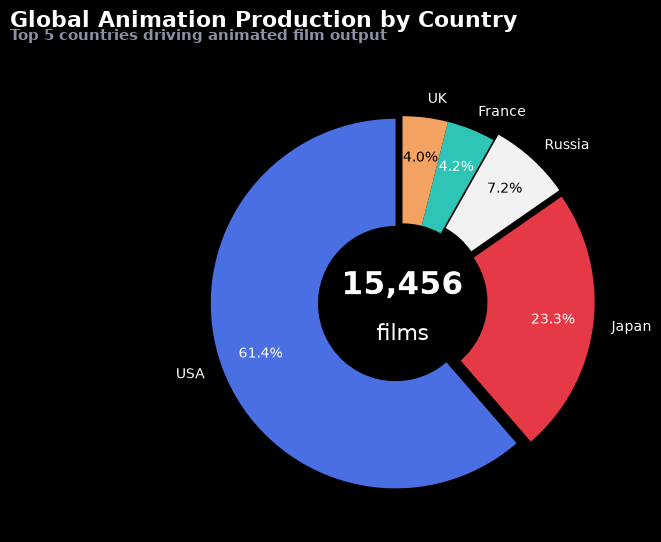

In [10]:
# ── VIZ 8: Donut chart — country influence (Top 5 only) ────────────────────
country_counts = df['Country_Origin'].value_counts()

# Top 5 only
top_n = 5
data_pie = country_counts.head(top_n)

# Colors looked up by country name so they match the bar chart
pie_colors = [COUNTRY_COLORS.get(c, DEFAULT_COLOR) for c in data_pie.index]

# Slight explode on the top 3
explode = [0.04 if i < 3 else 0 for i in range(len(data_pie))]

fig, ax_donut = plt.subplots(figsize=(10, 6))

wedges, texts, autotexts = ax_donut.pie(
    data_pie.values,
    labels=data_pie.index,
    autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
    pctdistance=0.78,
    colors=pie_colors,
    startangle=90,
    explode=explode,
    wedgeprops=dict(width=0.58, linewidth=2.5)
)

# Dark percentage labels on light wedges (e.g. white Russia) so they stay readable
for wedge, autotext in zip(wedges, autotexts):
    r, g, b, _ = wedge.get_facecolor()
    if 0.299 * r + 0.587 * g + 0.114 * b > 0.6:
        autotext.set_color('black')

# Centre
total = data_pie.sum()
ax_donut.text(0, 0.08, f'{total:,.0f}', ha='center', va='center',
              fontsize=22, fontweight='bold')
ax_donut.text(0, -0.18, 'films', ha='center', va='center',
              fontsize=16)

fig.suptitle(
    "Global Animation Production by Country",
    fontsize=16,
    weight="bold",
    x=0.12,
    ha="left",
    y=0.98
)

fig.text(
    0.12, 0.93,
    "Top 5 countries driving animated film output",
    fontsize=11,
    color=GRAY,
    weight='bold',
    ha="left"
)

C:\Users\jzhan\AppData\Local\Temp\ipykernel_30004\2742159596.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(top10['Movie_Name'], fontsize=10)


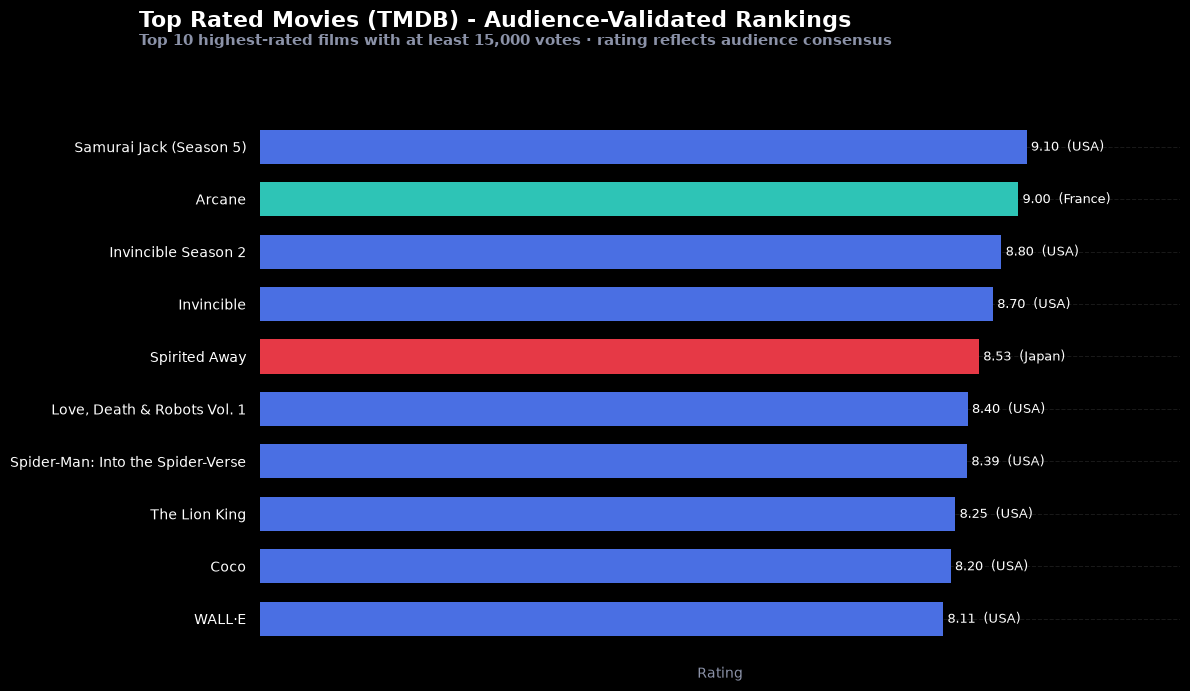

In [11]:
df_rated = df[
    (df['TMDB_Vote_Count'] >= 15000) &
    df['TMDB_Rating'].notna()
].copy()

top10 = df_rated.nlargest(10, 'TMDB_Rating').sort_values('TMDB_Rating')

bar_colors = [COUNTRY_COLORS.get(row['Country_Origin'], DEFAULT_COLOR)
              for _, row in top10.iterrows()]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top10['Movie_Name'], top10['TMDB_Rating'],
    color=bar_colors, height=0.65, linewidth=0.5, zorder=3
)

for bar, (_, row) in zip(bars, top10.iterrows()):
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2,
            f'{w:.2f}  ({row["Country_Origin"]})',
            va='center', fontsize=9)

fig.suptitle(
    "Top Rated Movies (TMDB) - Audience-Validated Rankings",
    fontsize=16,
    weight="bold",
    x=0.12,
    ha="left",
    y=0.98
)

fig.text(
    0.12, 0.93,
    "Top 10 highest-rated films with at least 15,000 votes · rating reflects audience consensus",
    weight='bold',
    fontsize=11,
    color=GRAY,
    ha="left"
)


ax.tick_params(axis='y', which='both', length=0, pad=10)
ax.tick_params(axis='x', which='both', length=0, pad=10)
plt.xticks([])

ax.set_xlim(0, top10['TMDB_Rating'].max() * 1.2)
ax.set_yticklabels(top10['Movie_Name'], fontsize=10)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0.1)
plt.xlabel("Rating", color=GRAY)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

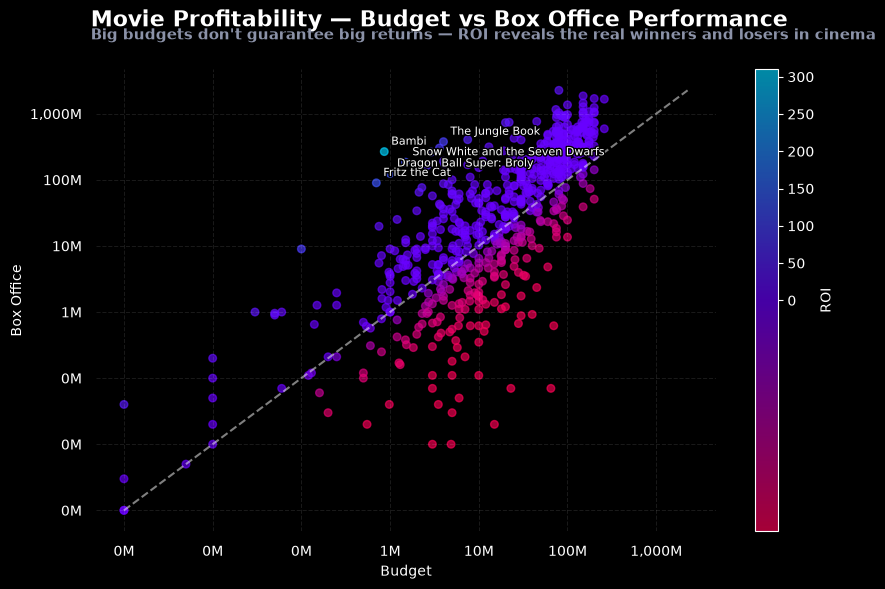

In [12]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patheffects as pe
import seaborn as sns

df_budget = df[
    df['Budget_Million_USD'].notna() &
    df['Box_Office_Million_USD'].notna() &
    (df['Budget_Million_USD'] > 0) &
    (df['Box_Office_Million_USD'] > 0)
].copy()

df_budget['ROI'] = (
    df_budget['Box_Office_Million_USD'] - df_budget['Budget_Million_USD']
) / df_budget['Budget_Million_USD']

fig, ax = plt.subplots(figsize=(10, 6))

cmap = mcolors.LinearSegmentedColormap.from_list(
    "cinema_roi",
    ["#ff0055", "#6a00ff", "#00d4ff"]
)

norm = mcolors.TwoSlopeNorm(
    vmin=df_budget['ROI'].min(),
    vcenter=0,
    vmax=df_budget['ROI'].max()
)

sc = ax.scatter(
    df_budget['Budget_Million_USD'],
    df_budget['Box_Office_Million_USD'],
    c=df_budget['ROI'],
    cmap=cmap,
    norm=norm,
    alpha=0.65,
    s=30
)

min_val = min(
    df_budget['Budget_Million_USD'].min(),
    df_budget['Box_Office_Million_USD'].min()
)
max_val = max(
    df_budget['Budget_Million_USD'].max(),
    df_budget['Box_Office_Million_USD'].max()
)

ax.plot([min_val, max_val], [min_val, max_val],
        linestyle='--', color='white', alpha=0.5)

ax.set_xscale('log')
ax.set_yscale('log')

ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}M")
)
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda y, _: f"{int(y):,}M")
)

ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_minor_locator(mticker.NullLocator())

top5 = df_budget.nlargest(5, 'ROI')

for _, row in top5.iterrows():
    ax.annotate(
        row['Movie_Name'],
        (row['Budget_Million_USD'], row['Box_Office_Million_USD']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8,
        color="white",
        path_effects=[pe.withStroke(linewidth=2, foreground='black')]
    )

ax.set_xlabel("Budget")
ax.set_ylabel("Box Office")

fig.suptitle(
    "Movie Profitability — Budget vs Box Office Performance",
    fontsize=16,
    weight="bold",
    x=0.12,
    ha="left",
    y=0.98
)

fig.text(
    0.12, 0.93,
    "Big budgets don't guarantee big returns — ROI reveals the real winners and losers in cinema",
    weight="bold",
    fontsize=11,
    color=GRAY,
    ha="left"
)

sns.despine()
ax.tick_params(axis='y', which='both', length=0, pad=10)
ax.tick_params(axis='x', which='both', length=0, pad=10)

plt.colorbar(sc, ax=ax, label="ROI")
sns.despine(left=True, bottom=True)
plt.grid(alpha=0.1, ls='--')

plt.show()

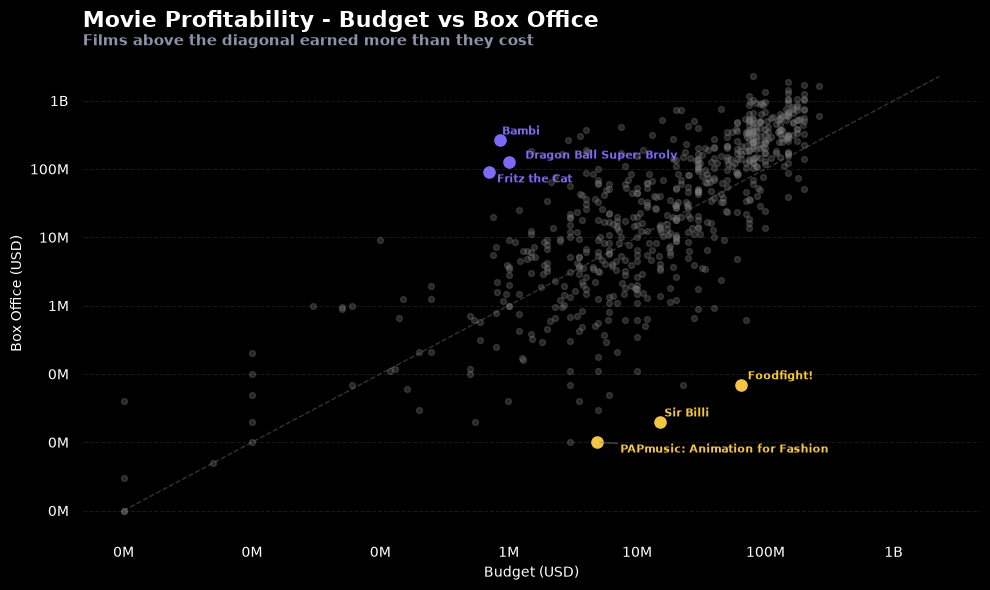

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from adjustText import adjust_text
import seaborn as sns
 
df_budget = df[
    df['Budget_Million_USD'].notna() &
    df['Box_Office_Million_USD'].notna() &
    (df['Budget_Million_USD'] > 0) &
    (df['Box_Office_Million_USD'] > 0)
].copy()
 
df_budget['log_dist'] = (
    np.log10(df_budget['Box_Office_Million_USD']) -
    np.log10(df_budget['Budget_Million_USD'])
)
 
# Select the 3 best and 3 worst ROI
gems  = df_budget.nlargest(3, 'log_dist')
flops = df_budget.nsmallest(3, 'log_dist')
 
fig, ax = plt.subplots(figsize=(10, 6))
 
# Points
others = df_budget[~df_budget.index.isin(gems.index.tolist() + flops.index.tolist())]
ax.scatter(others['Budget_Million_USD'], others['Box_Office_Million_USD'],
           color='gray', alpha=0.3, s=18)
ax.scatter(gems['Budget_Million_USD'],  gems['Box_Office_Million_USD'],
           color=C1, s=65)
ax.scatter(flops['Budget_Million_USD'], flops['Box_Office_Million_USD'],
           color=C4, s=65)
 
lim = [df_budget[['Budget_Million_USD','Box_Office_Million_USD']].min().min(),
       df_budget[['Budget_Million_USD','Box_Office_Million_USD']].max().max()]
ax.plot(lim, lim, '--', color='gray', linewidth=1, alpha=0.4)
 
ax.set_xscale('log')
ax.set_yscale('log')
 
def fmt(x, _):
    return f"{int(x)}M" if x < 1000 else f"{int(x/1000)}B"
 
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt))
 
texts = []
for _, row in gems.iterrows():
    texts.append(ax.text(row['Budget_Million_USD'], row['Box_Office_Million_USD'],
                         row['Movie_Name'], color=C1, fontsize=8, fontweight='bold'))
for _, row in flops.iterrows():
    texts.append(ax.text(row['Budget_Million_USD'], row['Box_Office_Million_USD'],
                         row['Movie_Name'], color=C4, fontsize=8, fontweight='bold'))
 
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', alpha=0.5))
 
plt.title("Movie Profitability - Budget vs Box Office",
          fontsize=16,
          weight="bold",
          loc="left",
          pad=20)
 
plt.text(0, 1.02,
         "Films above the diagonal earned more than they cost",
         transform=ax.transAxes,
         weight="bold",
         fontsize=11,
         color=GRAY)
 
ax.set_xlabel("Budget (USD)")
ax.set_ylabel("Box Office (USD)")
 
sns.despine(left=True, bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.1)
 
ax.tick_params(axis='y', which='both', length=0, pad=10)
ax.tick_params(axis='x', which='both', length=0, pad=10)
 
plt.tight_layout()
plt.show()

In [14]:
df['Studio'] = df['Studio'].replace({
    'Disney Television Animation': 'The Walt Disney Company',
    'Walt Disney Productions': 'The Walt Disney Company',
    'Warner Bros. Animation': 'Warner Bros.',
    'Warner Bros. Pictures': 'Warner Bros.',
    'Warner Bros. Cartoons': 'Warner Bros.'
})

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


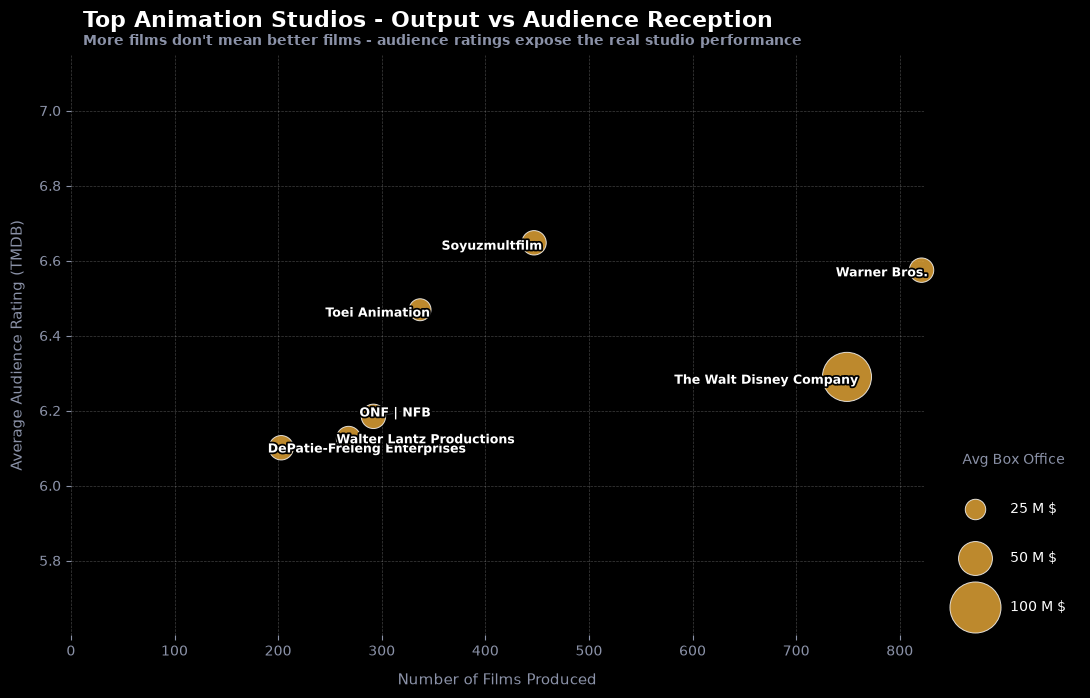

In [15]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# Colors
BUBBLE    = "#e8a838"
BUBBLE_ED = "#ffffff"

# Top studios
top_studios = df['Studio'].value_counts().head(10).index
df_studio   = df[df['Studio'].isin(top_studios)].copy()

# Aggregation
summary = df_studio.groupby('Studio').agg(
    movies     = ('Movie_Name', 'count'),
    rating     = ('TMDB_Rating', 'mean'),
    box_office = ('Box_Office_Million_USD', 'mean')
).reset_index()

# Filter
summary = summary[summary['rating'] >= 6.0]

# Bubble sizes (safe scaling)
bo = summary['box_office'].fillna(summary['box_office'].median())

if bo.max() == bo.min():
    sizes = np.full(len(bo), 600)
else:
    sizes = (bo - bo.min()) / (bo.max() - bo.min()) * 1000 + 250

# Plot
fig, ax = plt.subplots(figsize=(11, 7))

sc = ax.scatter(
    summary['movies'],
    summary['rating'],
    s=sizes,
    alpha=0.82,
    color=BUBBLE,
    edgecolors=BUBBLE_ED,
    linewidth=0.7,
    clip_on=False,
    zorder=3
)

# Labels
texts = []
for _, row in summary.iterrows():
    t = ax.text(
        row['movies'],
        row['rating'],
        row['Studio'],
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=5,
        color="white"  # white text
    )
    t.set_path_effects([
        pe.withStroke(linewidth=2.5, foreground="black")  # black outline
    ])
    texts.append(t)

# Adjust labels
adjust_text(
    texts,
    x=summary['movies'].values,
    y=summary['rating'].values,
    ax=ax,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    force_points=(0.2, 0.2),
    arrowprops=dict(
        arrowstyle="-",
        color=GRAY,
        lw=0.6,
        alpha=0.4,
    ),
)

# Axes styling
ax.set_xlabel("Number of Films Produced", fontsize=11, labelpad=10, color=GRAY)
ax.set_ylabel("Average Audience Rating (TMDB)", fontsize=11, labelpad=10, color=GRAY)
ax.tick_params(colors=GRAY)

for spine in ax.spines.values():
    spine.set_visible(False)

# Titles
fig.suptitle(
    "Top Animation Studios - Output vs Audience Reception",
    fontsize=16,
    weight="bold",
    x=0.08,
    ha="left",
    y=0.99
)

fig.text(
    0.08,
    0.94,
    "More films don't mean better films - audience ratings expose the real studio performance",
    fontsize=10,
    weight = 'bold',
    color=GRAY,
    ha="left"
)

# Legend
legend_vals = [25, 50, 100]

if bo.max() == bo.min():
    legend_sizes_l = [600, 600, 600]
else:
    legend_sizes_l = [(v - bo.min()) / (bo.max() - bo.min()) * 1000 + 250 for v in legend_vals]

legend_handles = [
    plt.scatter([], [], s=s, color=BUBBLE, alpha=0.82,
                edgecolors=BUBBLE_ED, linewidth=0.7)
    for s in legend_sizes_l
]

legend_labels = [f"{v:.0f} M $" for v in legend_vals]

leg = ax.legend(
    legend_handles,
    legend_labels,
    title="Avg Box Office",
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    frameon=False,
    labelspacing=2.5,
    handletextpad=1.5,
    borderpad=1,
)

leg.get_title().set_color(GRAY)

# Grid
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.25)

# Limits
ax.set_xlim(0, summary['movies'].max() + 2)
ax.set_ylim(summary['rating'].min() - 0.5, summary['rating'].max() + 0.5)

plt.tight_layout()
plt.show()